# TTC Streetcar Delay Analysis
Analyzing Toronto streetcar delays (2025 to 2026) using Python, Pandas and SQL.

In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3
from pathlib import Path

Path("charts").mkdir(exist_ok=True)

print(pd.__version__)

3.0.3


## Step 2: Load the data

In [8]:
df = pd.read_csv("ttc_streetcar_delays.csv")
df.shape

(24764, 11)

In [9]:
df.head()

,_id,Date,Line,Time,Day,Station,Code,Min Delay,Min Gap,Bound,Vehicle
0,1,2025-01-01,504 KING,02:10,Wednesday,KING AND PARLIAMENT,MTSAN,10,20,W,4569
1,2,2025-01-01,506 CARLTON,02:50,Wednesday,COLLEGE AND HURON,MTAFR,34,49,E,4480
2,3,2025-01-01,504 KING,03:11,Wednesday,KING AND QUEEN EAST,MTIE,15,30,E,4629
3,4,2025-01-01,501 QUEEN,05:14,Wednesday,QUEEN AND DUFFERIN,MTAFR,36,55,E,4455
4,5,2025-01-01,504 KING,06:14,Wednesday,LESLIE CARHOUSE,MTVIS,10,20,E,4483


## Step 3: Get to know the data

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24764 entries, 0 to 24763
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   _id        24764 non-null  int64
 1   Date       24764 non-null  str  
 2   Line       24402 non-null  str  
 3   Time       24764 non-null  str  
 4   Day        24764 non-null  str  
 5   Station    24764 non-null  str  
 6   Code       24763 non-null  str  
 7   Min Delay  24764 non-null  int64
 8   Min Gap    24764 non-null  int64
 9   Bound      19093 non-null  str  
 10  Vehicle    24764 non-null  int64
dtypes: int64(4), str(7)
memory usage: 3.4 MB


In [11]:
df.isna().sum()

_id             0
Date            0
Line          362
Time            0
Day             0
Station         0
Code            1
Min Delay       0
Min Gap         0
Bound        5671
Vehicle         0
dtype: int64

In [12]:
df[["Min Delay", "Min Gap"]].describe()

,Min Delay,Min Gap
count,24764.000000,24764.000000
mean,17.574786,24.890284
std,38.710009,39.707294
min,0.000000,0.000000
25%,5.000000,10.000000
50%,10.000000,20.000000
75%,16.000000,26.000000
max,999.000000,999.000000


## Step 4: Find data quality problems

In [13]:
df["Min Delay"].sort_values(ascending=False).head(20)

17281    999
16817    922
2708     840
2789     840
2126     831
24540    824
18764    823
174      780
16281    740
16280    740
2658     738
13017    726
5496     696
1530     694
11379    690
22879    651
2741     600
17032    600
17358    597
17405    591
Name: Min Delay, dtype: int64

In [14]:
print("Delays of 0 minutes:", (df["Min Delay"] == 0).sum())
print("Delays over 300 minutes:", (df["Min Delay"] > 300).sum())

Delays of 0 minutes: 5530
Delays over 300 minutes: 82


In [15]:
print("Distinct lines:", df["Line"].nunique())
df["Line"].value_counts()

Distinct lines: 204


Line
504 KING                 4246
501 QUEEN                4197
505 DUNDAS               3363
506 CARLTON              3103
503 KINGSTON ROAD        1869
                         ... 
929                         1
504 KING- RAD               1
RAD CAR                     1
501 QUEEN (RAD)             1
501 QUEEN REPLACEMENT       1
Name: count, Length: 204, dtype: int64

In [16]:
df["Bound"].value_counts(dropna=False)

Bound
W      7156
E      7048
NaN    5671
S      2448
N      2424
B        16
8         1
Name: count, dtype: int64

In [17]:
df.drop(columns="_id").duplicated().sum()

np.int64(20)

## Step 5: Clean the data

| Problem | Decision |
|---|---|
| Line has non-route values (RAD CAR, 929, etc.) | Keep only routes 501-512 and 301-312 |
| Min Delay = 0 | Keep for incident counts, exclude from delay averages |
| Min Delay over 300 | Exclude from delay analysis (likely placeholder like 999) |
| Duplicate rows | Remove |
| Date and Time stored as text | Convert to a real datetime |

In [19]:
clean = df.copy()

clean = clean.rename(columns={
    "_id": "id",
    "Date": "date",
    "Line": "line_raw",
    "Time": "time",
    "Day": "day",
    "Station": "location",
    "Code": "code",
    "Min Delay": "min_delay",
    "Min Gap": "min_gap",
    "Bound": "bound",
    "Vehicle": "vehicle",
})

clean.columns

Index(['id', 'date', 'line_raw', 'time', 'day', 'location', 'code',
       'min_delay', 'min_gap', 'bound', 'vehicle'],
      dtype='str')

In [20]:
before = len(clean)
clean = clean.drop_duplicates(subset=clean.columns.drop("id"))
print("Removed", before - len(clean), "duplicate rows")

Removed 20 duplicate rows


In [21]:
clean["datetime"] = pd.to_datetime(clean["date"] + " " + clean["time"])

clean[["date", "time", "datetime"]].head()

,date,time,datetime
0,2025-01-01,02:10,2025-01-01 02:10:00
1,2025-01-01,02:50,2025-01-01 02:50:00
2,2025-01-01,03:11,2025-01-01 03:11:00
3,2025-01-01,05:14,2025-01-01 05:14:00
4,2025-01-01,06:14,2025-01-01 06:14:00


In [23]:
clean["datetime"].dtype.name

'datetime64[us]'

In [24]:
clean["route_number"] = (
    clean["line_raw"]
    .str.extract(r"^\s*(\d{3})", expand=False)
    .astype("Int64")
)

clean[["line_raw", "route_number"]].sample(10)

,line_raw,route_number
11294,503 KINGSTON ROAD,503
11155,510 SPADINA,510
19095,501 QUEEN,501
13497,301 QUEEN NIGHT,301
15,511 BATHURST,511
14846,504 KING,504
11892,510 SPADINA,510
13515,507 LONG BRANCH,507
13596,511 BATHURST,511
18447,506 CARLTON,506


In [26]:
is_day_route = clean["route_number"].between(501, 512)
is_night_route = clean["route_number"].between(301, 312)

before = len(clean)
clean = clean[is_day_route | is_night_route].copy()
print("Removed", before - len(clean), "non-streetcar rows")

Removed 692 non-streetcar rows


In [27]:
clean["route_number"].value_counts().sort_index()

route_number
301     295
303      44
304     167
305     181
306     182
309       2
310      61
311       4
312      32
501    4201
502       1
503    1875
504    4272
505    3370
506    3114
507     864
508     110
509     632
510    1833
511    1097
512    1715
Name: count, dtype: Int64

In [28]:
route_names = (
    clean.groupby("route_number")["line_raw"]
    .agg(lambda s: s.mode()[0])
    .str.strip()
    .str.title()
)

route_names

route_number
301           301 Queen Night
303    303 Kingston Road Nigh
304            304 King Night
305          305 Dundas Night
306         306 Carlton Night
309          309 Harbourfront
310         310 Spadina Night
311                       311
312       312 St. Clair Night
501                 501 Queen
502            502 Downtowner
503         503 Kingston Road
504                  504 King
505                505 Dundas
506               506 Carlton
507           507 Long Branch
508             508 Lakeshore
509          509 Harbourfront
510               510 Spadina
511              511 Bathurst
512             512 St. Clair
Name: line_raw, dtype: str

In [29]:
def fix_name(number, name):
    if number < 500 and not name.endswith("Night"):
        name = name.replace("Nigh", "").strip() + " Night"
    return name

route_names = pd.Series(
    [fix_name(n, name) for n, name in route_names.items()],
    index=route_names.index,
)

In [30]:
clean["route"] = clean["route_number"].map(route_names)

clean[["line_raw", "route_number", "route"]].sample(10)

,line_raw,route_number,route
16185,501 QUEEN,501,501 Queen
11380,501 QUEEN,501,501 Queen
14502,505 DUNDAS,505,505 Dundas
23540,506 CARLTON,506,506 Carlton
21042,506 CARLTON,506,506 Carlton
2480,506 CARLTON,506,506 Carlton
5248,505 DUNDAS,505,505 Dundas
12270,509 HARBOURFRONT,509,509 Harbourfront
4755,505 DUNDAS,505,505 Dundas
7847,507 LONG BRANCH,507,507 Long Branch


In [31]:
clean.loc[clean["route_number"] < 500, "route"].unique()

<ArrowStringArray>
[       '305 Dundas Night',          '304 King Night',
 '303 Kingston Road Night',         '301 Queen Night',
       '306 Carlton Night',       '310 Spadina Night',
     '312 St. Clair Night',               '311 Night',
  '309 Harbourfront Night']
Length: 9, dtype: str

In [32]:
# Direction: anything that isn't N, S, E or W becomes "Unknown"
clean["bound"] = clean["bound"].where(clean["bound"].isin(["N", "S", "E", "W"]), "Unknown")

# Vehicle number 0 isn't real, so mark it as missing
clean["vehicle"] = clean["vehicle"].replace(0, pd.NA)

# One row has no code
clean["code"] = clean["code"].fillna("UNKNOWN")

clean["bound"].value_counts()

bound
W          7094
E          6976
Unknown    5214
S          2403
N          2365
Name: count, dtype: int64

In [33]:
clean["is_valid_delay"] = clean["min_delay"].between(1, 300)

clean["is_valid_delay"].value_counts()

is_valid_delay
True     19035
False     5017
Name: count, dtype: int64

## Step 6: Feature engineering

In [34]:
clean["year"] = clean["datetime"].dt.year
clean["month"] = clean["datetime"].dt.month
clean["hour"] = clean["datetime"].dt.hour
clean["year_month"] = clean["datetime"].dt.strftime("%Y-%m")

clean[["datetime", "year", "month", "hour", "year_month"]].head()

,datetime,year,month,hour,year_month
0,2025-01-01 02:10:00,2025,1,2,2025-01
1,2025-01-01 02:50:00,2025,1,2,2025-01
2,2025-01-01 03:11:00,2025,1,3,2025-01
3,2025-01-01 05:14:00,2025,1,5,2025-01
4,2025-01-01 06:14:00,2025,1,6,2025-01


In [35]:
clean["is_weekend"] = clean["day"].isin(["Saturday", "Sunday"])
clean["service"] = clean["route_number"].apply(lambda n: "Night" if n < 500 else "Day")

clean[["day", "is_weekend", "route", "service"]].sample(8)

,day,is_weekend,route,service
3152,Thursday,False,504 King,Day
17120,Friday,False,506 Carlton,Day
16108,Sunday,True,504 King,Day
2212,Wednesday,False,503 Kingston Road,Day
3302,Monday,False,512 St. Clair,Day
6789,Sunday,True,501 Queen,Day
8391,Friday,False,512 St. Clair,Day
10995,Tuesday,False,510 Spadina,Day


In [36]:
clean["period"] = pd.cut(
    clean["hour"],
    bins=[-1, 5, 9, 14, 18, 23],
    labels=["Overnight (0-5)", "AM Rush (6-9)", "Midday (10-14)", "PM Rush (15-18)", "Evening (19-23)"],
)

clean["period"].value_counts()

period
Overnight (0-5)    5741
Evening (19-23)    5054
Midday (10-14)     5006
PM Rush (15-18)    4586
AM Rush (6-9)      3665
Name: count, dtype: int64

In [37]:
clean = clean[[
    "id", "datetime", "year", "month", "year_month", "day", "is_weekend", "hour", "period",
    "route_number", "route", "service", "location", "bound", "code",
    "min_delay", "min_gap", "vehicle", "is_valid_delay",
]]

delays = clean[clean["is_valid_delay"]].copy()

print("All incidents:", clean.shape)
print("Valid delays: ", delays.shape)

All incidents: (24052, 19)
Valid delays:  (19035, 19)


In [38]:
total_incidents = len(delays)
total_minutes = delays["min_delay"].sum()
avg_delay = delays["min_delay"].mean()
median_delay = delays["min_delay"].median()

print(f"Total delays:   {total_incidents:,}")
print(f"Minutes lost:   {total_minutes:,} (about {total_minutes / 60:,.0f} hours)")
print(f"Average delay:  {avg_delay:.1f} min")
print(f"Median delay:   {median_delay:.0f} min")

Total delays:   19,035
Minutes lost:   392,407 (about 6,540 hours)
Average delay:  20.6 min
Median delay:   10 min


## Step 8: Delays by route

In [39]:
by_route = (
    delays.groupby("route")
    .agg(
        incidents=("id", "count"),
        total_minutes=("min_delay", "sum"),
        avg_delay=("min_delay", "mean"),
    )
    .sort_values("total_minutes", ascending=False)
    .round(1)
)

by_route

,incidents,total_minutes,avg_delay
route,,,
501 Queen,3409,71575,21.0
504 King,3362,68388,20.3
505 Dundas,2593,56967,22.0
506 Carlton,2479,56573,22.8
503 Kingston Road,1593,28364,17.8
512 St. Clair,1361,24380,17.9
510 Spadina,1410,20217,14.3
511 Bathurst,858,17485,20.4
507 Long Branch,713,14016,19.7


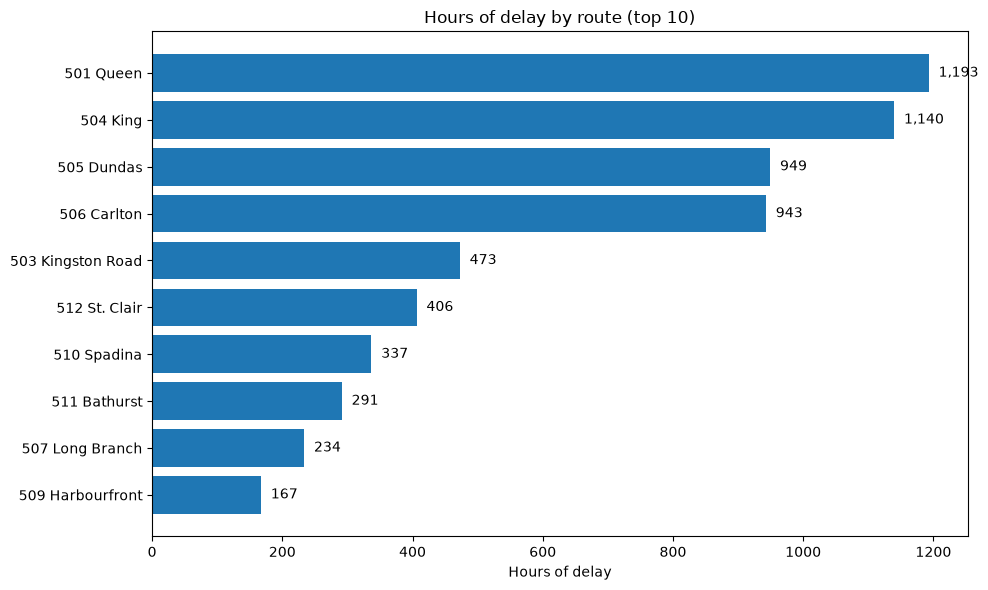

In [69]:
top = by_route.head(10).sort_values("total_minutes")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.index, top["total_minutes"] / 60)
ax.set_title("Hours of delay by route (top 10)")
ax.set_xlabel("Hours of delay")
for i, v in enumerate(top["total_minutes"] / 60):
    ax.text(v + 15, i, f"{v:,.0f}", va="center")
plt.tight_layout()
plt.savefig("charts/01_hours_by_route.png", dpi=150)
plt.show()

### Same question in SQL

In [42]:
conn = sqlite3.connect(":memory:")

clean.astype({"datetime": "str", "period": "str"}).to_sql("delays", conn, index=False)

def sql(query):
    return pd.read_sql(query, conn)

sql("SELECT COUNT(*) AS total_rows FROM delays")

,total_rows
0,24052


In [43]:
route_sql = sql("""
    SELECT
        route,
        COUNT(*)                 AS incidents,
        SUM(min_delay)           AS total_minutes,
        ROUND(AVG(min_delay), 1) AS avg_delay
    FROM delays
    WHERE is_valid_delay = 1
    GROUP BY route
    ORDER BY total_minutes DESC
""")

route_sql

,route,incidents,total_minutes,avg_delay
0,501 Queen,3409,71575,21.0
1,504 King,3362,68388,20.3
2,505 Dundas,2593,56967,22.0
3,506 Carlton,2479,56573,22.8
4,503 Kingston Road,1593,28364,17.8
5,512 St. Clair,1361,24380,17.9
6,510 Spadina,1410,20217,14.3
7,511 Bathurst,858,17485,20.4
8,507 Long Branch,713,14016,19.7
9,509 Harbourfront,479,10041,21.0


In [44]:
print("Pandas total minutes:", by_route["total_minutes"].sum())
print("SQL total minutes:   ", route_sql["total_minutes"].sum())

Pandas total minutes: 392407
SQL total minutes:    392407


## Step 9: Delays by hour of day

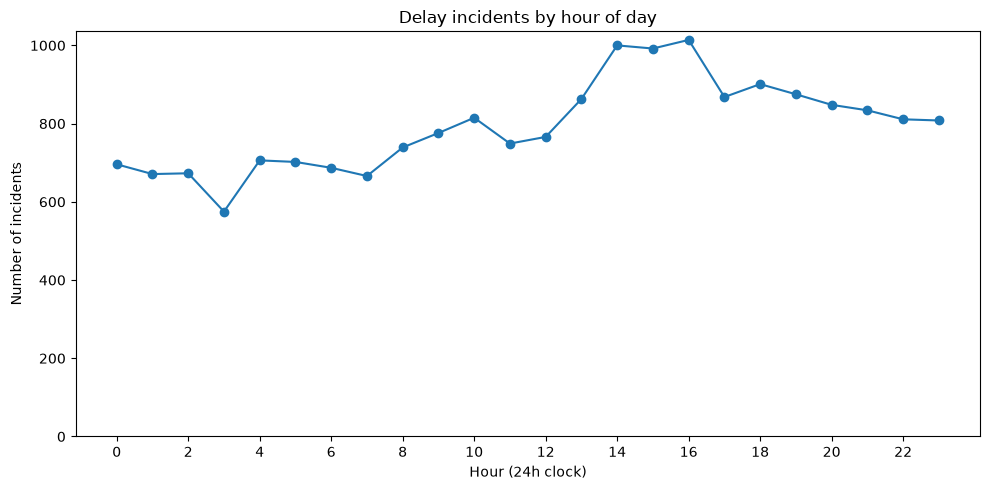

Peak hour: 16


In [70]:
by_hour = delays.groupby("hour").agg(
    incidents=("id", "count"),
    avg_delay=("min_delay", "mean"),
).round(1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(by_hour.index, by_hour["incidents"], marker="o")
ax.set_title("Delay incidents by hour of day")
ax.set_xlabel("Hour (24h clock)")
ax.set_ylabel("Number of incidents")
ax.set_xticks(range(0, 24, 2))
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.savefig("charts/02_incidents_by_hour.png", dpi=150)
plt.show()

print("Peak hour:", by_hour["incidents"].idxmax())

In [46]:
sql("""
    WITH labeled AS (
        SELECT
            min_delay,
            CASE
                WHEN hour BETWEEN 0  AND 5  THEN '1. Overnight'
                WHEN hour BETWEEN 6  AND 9  THEN '2. AM Rush'
                WHEN hour BETWEEN 10 AND 14 THEN '3. Midday'
                WHEN hour BETWEEN 15 AND 18 THEN '4. PM Rush'
                ELSE                             '5. Evening'
            END AS period,
            CASE
                WHEN hour BETWEEN 0  AND 5  THEN 6
                WHEN hour BETWEEN 6  AND 9  THEN 4
                WHEN hour BETWEEN 10 AND 14 THEN 5
                WHEN hour BETWEEN 15 AND 18 THEN 4
                ELSE                             5
            END AS hours_in_period
        FROM delays
        WHERE is_valid_delay = 1
    )
    SELECT
        period,
        COUNT(*)                                       AS incidents,
        ROUND(COUNT(*) * 1.0 / MAX(hours_in_period), 0) AS per_hour,
        ROUND(AVG(min_delay), 1)                       AS avg_delay
    FROM labeled
    GROUP BY period
    ORDER BY period
""")

,period,incidents,per_hour,avg_delay
0,1. Overnight,4023,671.0,23.4
1,2. AM Rush,2868,717.0,17.3
2,3. Midday,4193,839.0,19.5
3,4. PM Rush,3775,944.0,20.2
4,5. Evening,4176,835.0,21.7


## Step 10: Delays by day of week

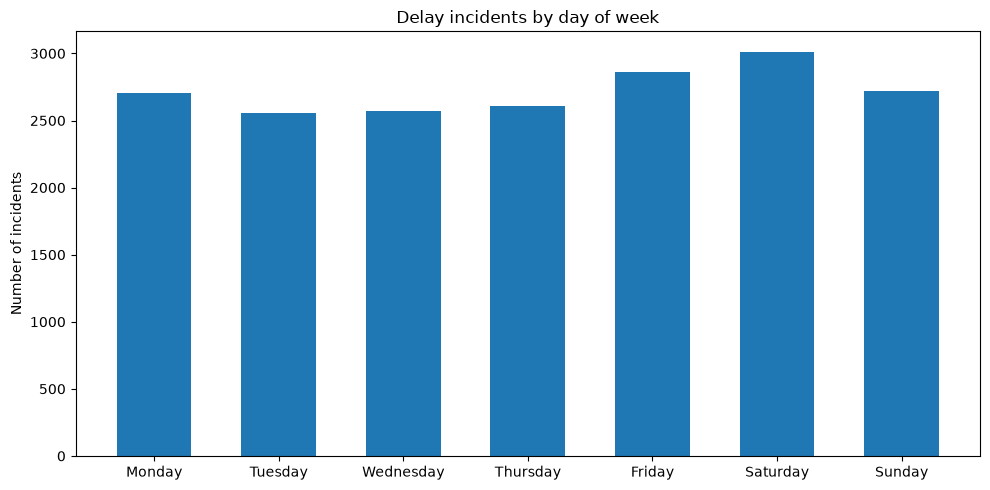

,incidents,avg_delay
day,,
Monday,2707,21.4
Tuesday,2555,19.8
Wednesday,2568,20.5
Thursday,2609,21.7
Friday,2863,20.3
Saturday,3014,19.8
Sunday,2719,20.8


In [71]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

by_day = (
    delays.groupby("day")
    .agg(incidents=("id", "count"), avg_delay=("min_delay", "mean"))
    .reindex(day_order)
    .round(1)
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(by_day.index, by_day["incidents"], width=0.6)
ax.set_title("Delay incidents by day of week")
ax.set_ylabel("Number of incidents")
plt.tight_layout()
plt.savefig("charts/03_incidents_by_day.png", dpi=150)
plt.show()

by_day

In [48]:
sql("""
    SELECT
        day,
        COUNT(*)                 AS incidents,
        ROUND(AVG(min_delay), 1) AS avg_delay
    FROM delays
    WHERE is_valid_delay = 1
    GROUP BY day
    ORDER BY CASE day
        WHEN 'Monday'    THEN 1
        WHEN 'Tuesday'   THEN 2
        WHEN 'Wednesday' THEN 3
        WHEN 'Thursday'  THEN 4
        WHEN 'Friday'    THEN 5
        WHEN 'Saturday'  THEN 6
        WHEN 'Sunday'    THEN 7
    END
""")

,day,incidents,avg_delay
0,Monday,2707,21.4
1,Tuesday,2555,19.8
2,Wednesday,2568,20.5
3,Thursday,2609,21.7
4,Friday,2863,20.3
5,Saturday,3014,19.8
6,Sunday,2719,20.8


## Step 11: Monthly trend and year-over-year comparison

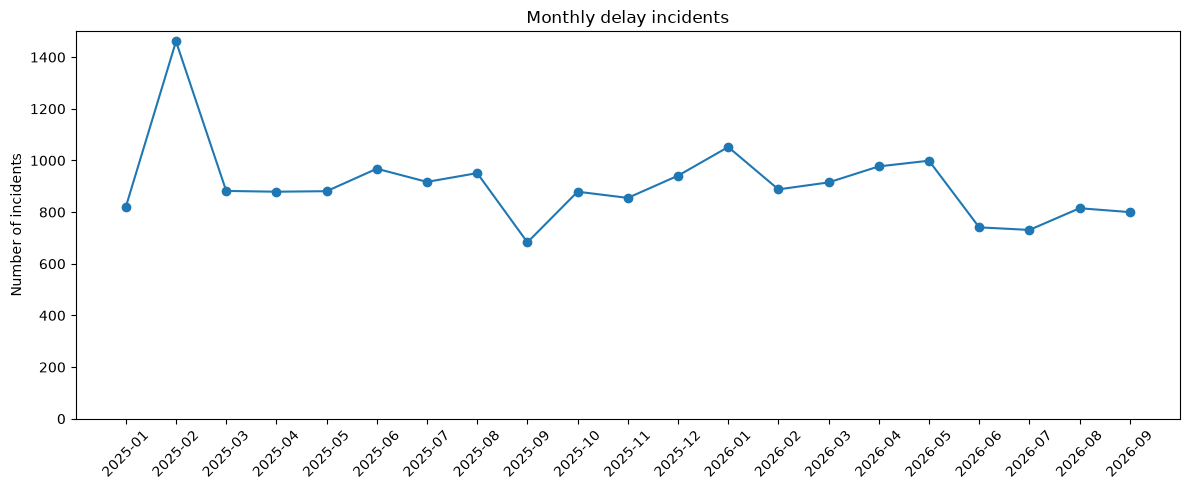

In [72]:
by_month = delays.groupby("year_month").agg(
    incidents=("id", "count"),
    total_minutes=("min_delay", "sum"),
)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(by_month.index, by_month["incidents"], marker="o")
ax.set_title("Monthly delay incidents")
ax.set_ylabel("Number of incidents")
ax.set_ylim(bottom=0)
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("charts/04_monthly_trend.png", dpi=150)
plt.show()

In [50]:
ytd = delays[delays["month"] <= 9]

yoy = ytd.groupby("year").agg(
    incidents=("id", "count"),
    total_minutes=("min_delay", "sum"),
    avg_delay=("min_delay", "mean"),
).round(1)

yoy.loc["% change"] = ((yoy.loc[2026] - yoy.loc[2025]) / yoy.loc[2025] * 100).round(1)

yoy

,incidents,total_minutes,avg_delay
year,,,
2025,8442.0,179323.0,21.2
2026,7918.0,161635.0,20.4
% change,-6.2,-9.9,-3.8


In [51]:
sql("""
    WITH monthly AS (
        SELECT year_month, COUNT(*) AS incidents
        FROM delays
        WHERE is_valid_delay = 1
        GROUP BY year_month
    )
    SELECT
        year_month,
        incidents,
        LAG(incidents) OVER (ORDER BY year_month) AS prev_month,
        incidents - LAG(incidents) OVER (ORDER BY year_month) AS change
    FROM monthly
    ORDER BY year_month
""")

,year_month,incidents,prev_month,change
0,2025-01,820,NaN,NaN
1,2025-02,1461,820.0,641.0
2,2025-03,882,1461.0,-579.0
3,2025-04,879,882.0,-3.0
4,2025-05,881,879.0,2.0
5,2025-06,968,881.0,87.0
6,2025-07,917,968.0,-51.0
7,2025-08,951,917.0,34.0
8,2025-09,683,951.0,-268.0
9,2025-10,879,683.0,196.0


In [52]:
feb_2025 = delays[delays["year_month"] == "2025-02"]

feb_2025.groupby(feb_2025["datetime"].dt.date).size().sort_values(ascending=False).head(10)

datetime
2025-02-17    97
2025-02-15    93
2025-02-22    91
2025-02-20    91
2025-02-14    85
2025-02-18    80
2025-02-21    78
2025-02-23    70
2025-02-13    67
2025-02-19    65
dtype: int64

## Step 12: Delay hotspots

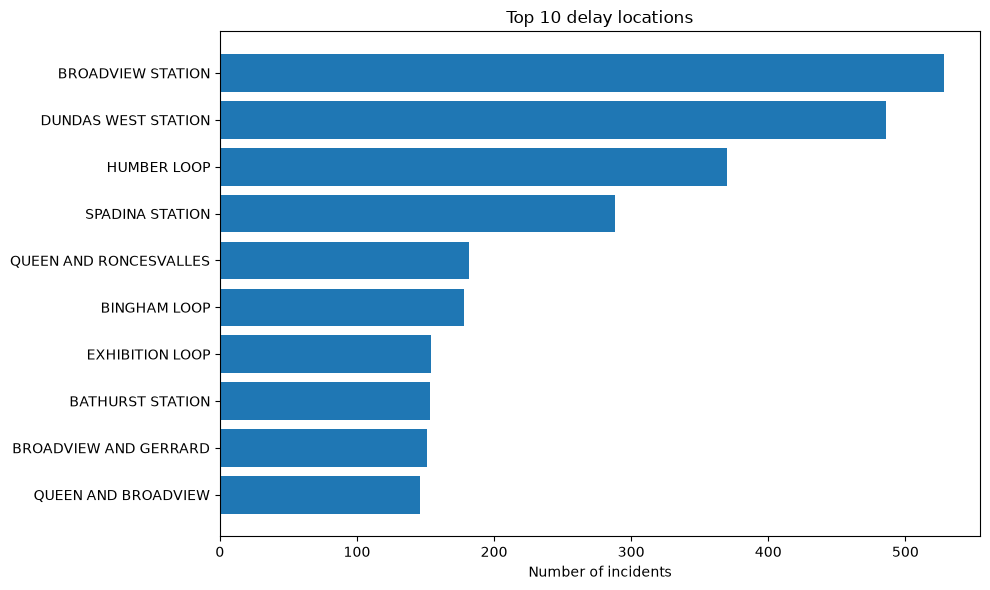

,incidents,total_minutes
location,,
BROADVIEW STATION,528,7456
DUNDAS WEST STATION,486,8515
HUMBER LOOP,370,6313
SPADINA STATION,288,3532
QUEEN AND RONCESVALLES,182,3046
BINGHAM LOOP,178,2693
EXHIBITION LOOP,154,1774
BATHURST STATION,153,2212
BROADVIEW AND GERRARD,151,3281


In [73]:
top_locations = (
    delays.groupby("location")
    .agg(incidents=("id", "count"), total_minutes=("min_delay", "sum"))
    .sort_values("incidents", ascending=False)
    .head(10)
)

chart = top_locations.sort_values("incidents")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(chart.index, chart["incidents"])
ax.set_title("Top 10 delay locations")
ax.set_xlabel("Number of incidents")
plt.tight_layout()
plt.savefig("charts/05_top_locations.png", dpi=150)
plt.show()

top_locations

In [54]:
sql("""
    WITH location_counts AS (
        SELECT route, location, COUNT(*) AS incidents
        FROM delays
        WHERE is_valid_delay = 1 AND service = 'Day'
        GROUP BY route, location
        HAVING COUNT(*) >= 20
    ),
    ranked AS (
        SELECT *,
               RANK() OVER (PARTITION BY route ORDER BY incidents DESC) AS rnk
        FROM location_counts
    )
    SELECT route, location, incidents
    FROM ranked
    WHERE rnk = 1
    ORDER BY incidents DESC
""")

,route,location,incidents
0,505 Dundas,BROADVIEW STATION,330
1,510 Spadina,SPADINA STATION,246
2,501 Queen,HUMBER LOOP,244
3,504 King,DUNDAS WEST STATION,181
4,503 Kingston Road,BINGHAM LOOP,176
5,511 Bathurst,BATHURST STATION,143
6,506 Carlton,MAIN STREET STATION,119
7,512 St. Clair,ST CLAIR WEST STATION,119
8,507 Long Branch,HUMBER LOOP,105
9,509 Harbourfront,EXHIBITION LOOP,69


## Step 13: Incident codes (Pareto analysis)

In [60]:
by_code = (
    delays.groupby("code")
    .agg(incidents=("id", "count"), total_minutes=("min_delay", "sum"), avg_delay=("min_delay", "mean"))
    .sort_values("total_minutes", ascending=False)
    .round(1)
)

by_code["pct_of_minutes"] = (by_code["total_minutes"] / by_code["total_minutes"].sum() * 100).round(1)
by_code["cumulative_pct"] = (by_code["total_minutes"].cumsum() / by_code["total_minutes"].sum() * 100).round(1)

by_code.head(10)

,incidents,total_minutes,avg_delay,pct_of_minutes,cumulative_pct
code,,,,,
MTDV,2334,92054,39.4,23.5,23.5
MTAFR,1231,37358,30.3,9.5,33.0
MTSAN,2341,25687,11.0,6.5,39.5
MTUI,1028,22108,21.5,5.6,45.2
TTPD,625,21826,34.9,5.6,50.7
STDP,1231,18451,15.0,4.7,55.4
MTUIR,778,11721,15.1,3.0,58.4
STO,611,10370,17.0,2.6,61.1
MTO,503,9556,19.0,2.4,63.5


In [56]:
codes_for_half = (by_code["cumulative_pct"] < 50).sum() + 1
print(f"{codes_for_half} of {len(by_code)} codes cause half of all lost minutes")

5 of 138 codes cause half of all lost minutes


In [57]:
sql("""
    WITH code_minutes AS (
        SELECT code, COUNT(*) AS incidents, SUM(min_delay) AS total_minutes
        FROM delays
        WHERE is_valid_delay = 1
        GROUP BY code
    )
    SELECT
        code,
        incidents,
        total_minutes,
        ROUND(100.0 * total_minutes / SUM(total_minutes) OVER (), 1) AS pct_of_minutes,
        ROUND(100.0 * SUM(total_minutes) OVER (ORDER BY total_minutes DESC)
              / SUM(total_minutes) OVER (), 1)                      AS cumulative_pct
    FROM code_minutes
    ORDER BY total_minutes DESC
    LIMIT 10
""")

,code,incidents,total_minutes,pct_of_minutes,cumulative_pct
0,MTDV,2334,92054,23.5,23.5
1,MTAFR,1231,37358,9.5,33.0
2,MTSAN,2341,25687,6.5,39.5
3,MTUI,1028,22108,5.6,45.2
4,TTPD,625,21826,5.6,50.7
5,STDP,1231,18451,4.7,55.4
6,MTUIR,778,11721,3.0,58.4
7,STO,611,10370,2.6,61.1
8,MTO,503,9556,2.4,63.5
9,MFDV,152,8640,2.2,65.7


## Step 14: Route × hour heatmap

In [61]:
heat = delays[(delays["service"] == "Day") & (delays["route_number"] != 502)].pivot_table(
    index="route",
    columns="hour",
    values="id",
    aggfunc="count",
    fill_value=0,
)

heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index]

heat

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
route,,,,,,,,,,,,,,,,,,,,,
501 Queen,128,139,110,84,104,136,130,121,143,132,...,176,168,183,127,140,161,150,150,168,179
504 King,113,167,134,95,112,141,144,119,128,137,...,167,167,148,136,142,147,142,129,143,159
505 Dundas,121,75,69,70,86,85,86,76,101,115,...,117,129,134,125,138,112,118,118,121,111
506 Carlton,107,75,59,56,76,74,83,86,101,118,...,139,121,141,111,104,122,116,152,107,113
503 Kingston Road,47,37,21,24,32,50,69,68,76,75,...,117,103,91,83,89,78,75,68,70,49
510 Spadina,54,32,25,15,31,51,34,41,60,65,...,72,78,82,81,89,69,69,73,55,62
512 St. Clair,25,29,23,17,34,28,46,52,49,41,...,109,108,111,85,73,99,81,46,54,44
511 Bathurst,41,35,17,4,9,30,28,41,28,34,...,48,49,62,42,46,30,39,38,39,44
507 Long Branch,29,24,22,18,29,39,25,24,29,38,...,32,32,31,30,39,28,37,35,32,21


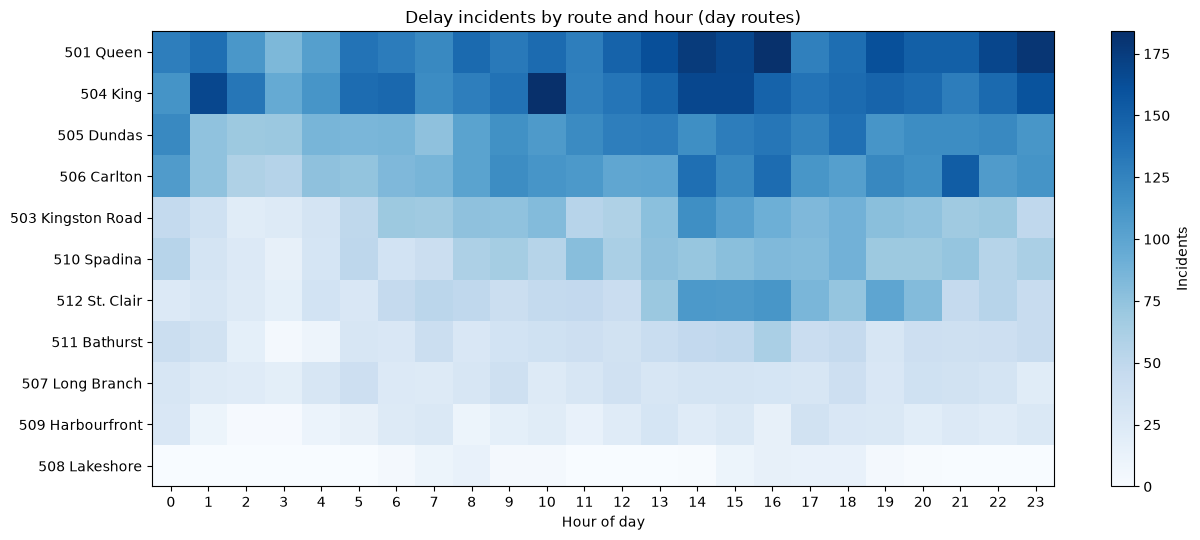

In [74]:
fig, ax = plt.subplots(figsize=(13, 5.5))
im = ax.imshow(heat, cmap="Blues", aspect="auto")

ax.set_xticks(range(24))
ax.set_xticklabels(range(24))
ax.set_yticks(range(len(heat)))
ax.set_yticklabels(heat.index)
ax.set_xlabel("Hour of day")
ax.set_title("Delay incidents by route and hour (day routes)")

fig.colorbar(im, ax=ax, label="Incidents")
plt.tight_layout()
plt.savefig("charts/06_route_hour_heatmap.png", dpi=150)
plt.show()

In [63]:
king_10am = delays[(delays["route_number"] == 504) & (delays["hour"] == 10)]

print("Top codes:")
print(king_10am["code"].value_counts().head(5))

print("\nTop days:")
print(king_10am.groupby(king_10am["datetime"].dt.date).size().sort_values(ascending=False).head(5))

Top codes:
code
MTDV     34
MTAFR    22
MTSAN    22
TFCNO    11
MTNOA     9
Name: count, dtype: int64

Top days:
datetime
2025-02-18    3
2025-10-31    3
2025-10-20    3
2025-08-16    3
2025-08-22    3
dtype: int64


## Step 15: Key Insights

### At a glance
| Total delays | Hours lost | Typical delay | Average delay |
|---|---|---|---|
| 19,035 | ~6,540 | 10 min (median) | 20.6 min |

*The average is about double the median because a small number of very long delays pull it up.*

---

### 🚋 Routes
**4 routes cause 65% of all lost time.**
501 Queen, 504 King, 505 Dundas and 506 Carlton together lose more time than every other route combined. 501 Queen alone lost about 1,190 hours.

### ⏰ Time of day
**Delays peak from 2 to 5 PM, not during the morning rush.**
The PM rush has the most delays per hour (~944), while the AM rush has the fewest (~717).

**Overnight delays are rarer but last the longest.**
Overnight delays average 23.4 min, compared with 17.3 min in the AM rush. Fewer streetcars and staff at night mean each delay takes longer to recover from.

### 📅 Day of week
**Saturday has the most delays, but the differences between days are small.**
Weekend construction and downtown events may play a role, but this data can't confirm it.

### 📈 Trend
**Things are improving: 2026 is down 6% on 2025.**
Comparing January to September in both years, incidents fell 6.2% and minutes lost fell 9.9%.

### ❄️ Weather
**One storm period drove the biggest spike in the data.**
February 2025 had about 1.7x the delays of a normal month. All 10 of its worst days fell between Feb 13 and 23, during back-to-back snowstorms. February 2026 was normal.

### 📍 Hotspots
**The worst locations are stations and loops, not busy intersections.**
Broadview Station, Dundas West Station, Humber Loop and Spadina Station top the list. These are turnaround and crew-change points, which suggests operational issues more than track problems.

### ⚠️ Causes
**5 of 138 incident codes cause half of all lost minutes.**
Code MTDV alone accounts for 23.5% of lost time, averaging 39 min per incident.

**How often isn't the same as how much damage.**
MTDV and MTSAN happen almost equally often, but MTDV costs 3.6x more time.

---

### Recommendations
1. **Focus on the big 4 routes.** Improvements to Queen, King, Dundas and Carlton would have the biggest impact on riders.
2. **Investigate code MTDV first.** Reducing it would do more than tackling any other single cause.
3. **Review operations at stations and loops,** especially crew changes and turnarounds at Broadview and Dundas West.
4. **Plan extra capacity for the 2 to 5 PM window,** when delays are most frequent.
5. **Strengthen the winter storm response.** One week of snow nearly doubled a month's delays.

### Limitations
- Incident codes (like MTDV) are abbreviations. Joining the TTC's code lookup table would show what each one means.
- Locations show where a delay was **recorded**, which isn't always where it started.
- Delays over 300 minutes and 0-minute delays were excluded from delay calculations as likely data errors or non-delays.
- The data shows what happened, not why. Explanations like weekend construction are possibilities, not confirmed causes.


## Step 16: Save outputs

In [67]:
from pathlib import Path

Path("outputs").mkdir(exist_ok=True)

clean.to_csv("outputs/ttc_delays_clean.csv", index=False)
by_route.to_csv("outputs/summary_by_route.csv")
by_code.to_csv("outputs/summary_by_code.csv")

print("Saved:")
for f in Path("outputs").glob("*.csv"):
    print("  ", f)

Saved:
   outputs\summary_by_code.csv
   outputs\summary_by_route.csv
   outputs\ttc_delays_clean.csv


In [75]:
conn.close()